# AGRIQO · Field Shift — Modèle des types de saison (v5, 30 saisons, référence fixe)

**But :** entraîner le meilleur modèle possible pour classer chaque saison agricole (octobre → mai) par **type de saison**, à partir des données NASA POWER.

**v5 :** même méthode que la v4 (tout le Maroc agricole), avec trois améliorations :
- **30 saisons** (1996–2025) au lieu de 10 : environ 3 fois plus d'exemples ;
- une **référence fixe** : le « normal » de chaque cellule est calculé une fois sur 1996–2025 et sauvegardé, pour que les nouvelles saisons soient toujours comparées à la même base ;
- des **features de calendrier** (pluie d'automne, pluie et chaleur de printemps), testées comme jeux supplémentaires dans la comparaison.

**Ce que fait le notebook :**
1. travaille sur des **anomalies** (chaque saison comparée au climat habituel de son lieu) ;
2. **compare plusieurs modèles** (jeux de features × K-Means / mélange gaussien × nombre de classes) ;
3. **choisit le meilleur** avec des règles écrites à l'avance : stable, équilibré par cellule, classes assez grandes, puis meilleure séparation ;
4. **nomme les classes d'après leur profil** (pluie et chaleur), pas d'après un ordre arbitraire ;
5. vérifie le modèle sur des **saisons jamais vues** (2024–2025) et sur des **lieux jamais vus**, puis le sauvegarde.

⏱️ Le téléchargement prend environ **15 à 30 minutes** la première fois (3 requêtes de 10 ans par cellule). Ensuite tout est en cache. La comparaison des 24 modèles prend quelques minutes.

**Sur Kaggle :** *Settings → Internet → On*, puis *Run All*.

> « Meilleur » veut dire : meilleur selon les critères de la section 5. Un score de séparation élevé ne suffit pas (la v1 avait une bonne silhouette mais séparait la montagne de la plaine).

## 1. Configuration

In [3]:
import json, time, itertools, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

START, END = "19951001", "20250930"        # 30 saisons : 1996 -> 2025
REF_SEASONS = (1996, 2025)                 # période de référence du « normal »
HOLDOUT_LAST = 5                           # saisons gardées pour le test « saisons jamais vues »
MIN_SEASONS = 24                           # une cellule doit avoir au moins 24 saisons valides sur 30
PARAMS = ["T2M", "T2M_MAX", "PRECTOTCORR", "GWETROOT"]
HEAT_T, DRY_MM, MAX_MISSING = 30.0, 1.0, 0.05
RANDOM_STATE = 42
FEATURES = ["rain_mm", "t_mean", "heat_days", "max_dry_spell", "gwetroot_mean",
            "rain_autumn", "rain_spring", "heat_spring"]
REFERENCE_POINT = ("Beni Mellal", 32.34, -6.35)

# --- Règles de sélection (fixées avant de regarder les résultats) ---
K_CANDIDATES = [3, 4]          # 3 ou 4 types de saison : assez pour être utile, assez peu pour être lisible
MIN_ARI_BOOT = 0.75            # stabilité minimale (ARI moyen sur rééchantillonnages)
MAX_SHARE_PER_CELL = 0.70      # une cellule est « dominée » si une classe y dépasse 70 %
MAX_FRAC_DOMINATED = 0.10      # au plus 10 % des cellules dominées
MIN_SEASON_RAIN = 100.0        # mm/saison : en dessous (désert), les anomalies de pluie n'ont pas de sens agricole
MIN_CLASS_SHARE = 0.10         # chaque classe contient au moins 10 % des saisons
N_BOOT = 30

OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "power_cache"; CACHE.mkdir(exist_ok=True)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


## 2. Grille sur le Maroc et données NASA POWER

La grille suit exactement les cellules de NASA POWER (0,5° × 0,625°). On garde les cellules qui tombent **au Maroc**, d'après les frontières Natural Earth, au nord de 29,5° N : c'est là que se trouve l'essentiel de l'agriculture pluviale. Les cellules trop sèches (désert) sont retirées plus loin, à la section 3.

In [4]:
LATS = [round(29.5 + 0.5 * i, 3) for i in range(13)]            # 29.5 -> 35.5
LONS = [round(-9.375 + 0.625 * j, 3) for j in range(14)]        # -9.375 -> -1.25
from matplotlib.path import Path as MplPath
NE_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson"

def morocco_paths():
    js = requests.get(NE_URL, timeout=60).json()
    feat = next(f for f in js["features"]
                if f["properties"].get("ADMIN") == "Morocco" or f["properties"].get("ISO_A3") == "MAR")
    g = feat["geometry"]
    polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
    return [MplPath(np.array(p[0])) for p in polys]

def in_country(paths, lat, lon, d=0.2):
    """Gardée si le centre est au Maroc, ou au moins 2 des 4 points voisins (cellules côtières)."""
    inside = lambda la, lo: any(p.contains_point((lo, la)) for p in paths)
    if inside(lat, lon): return True
    return sum(inside(lat + a, lon + b) for a in (-d, d) for b in (-d, d)) >= 2

try:
    paths = morocco_paths(); COUNTRY_FILTER = "Natural Earth 1:50m"
    grid = [(la, lo) for la in LATS for lo in LONS if in_country(paths, la, lo)]
except Exception as e:
    print("⚠️ Frontières indisponibles (", e, ") : grille rectangulaire, vérifiez la carte en 7.6")
    COUNTRY_FILTER = "aucun (rectangle)"; grid = [(la, lo) for la in LATS for lo in LONS]
points = [(f"C{i:03d}", la, lo) for i, (la, lo) in enumerate(grid)]
region = lambda lat: "Nord" if lat >= 34 else ("Centre" if lat >= 31.5 else "Sud")
print(f"{len(points)} cellules à télécharger (filtre pays : {COUNTRY_FILTER})")

114 cellules à télécharger (filtre pays : Natural Earth 1:50m)


In [5]:
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

def fetch_chunk(lat, lon, start, end, retries=3):
    f = CACHE / f"{lat:.3f}_{lon:.3f}_{start}_{end}.json"
    if f.exists():
        js = json.loads(f.read_text())
    else:
        params = dict(parameters=",".join(PARAMS), community="AG", latitude=lat,
                      longitude=lon, start=start, end=end, format="JSON")
        for attempt in range(retries):
            try:
                r = requests.get(POWER_URL, params=params, timeout=120)
                r.raise_for_status(); js = r.json(); break
            except Exception as e:
                print(f"  essai {attempt+1} échoué ({e})"); time.sleep(5 * (attempt + 1))
        else:
            raise RuntimeError(f"NASA POWER inaccessible pour {lat},{lon}")
        f.write_text(json.dumps(js)); time.sleep(1)
    df = pd.DataFrame({k: pd.Series(v) for k, v in js["properties"]["parameter"].items()})
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    return df.replace(-999, np.nan).sort_index()

def fetch_power(lat, lon, start=START, end=END):
    """Télécharge par tranches de 10 ans (requêtes plus courtes et plus sûres), puis assemble."""
    s0, e0 = pd.Timestamp(start), pd.Timestamp(end)
    parts, cur = [], s0
    while cur <= e0:
        nxt = min(cur + pd.DateOffset(years=10) - pd.Timedelta(days=1), e0)
        parts.append(fetch_chunk(lat, lon, cur.strftime("%Y%m%d"), nxt.strftime("%Y%m%d")))
        cur = nxt + pd.Timedelta(days=1)
    df = pd.concat(parts).sort_index()
    return df[~df.index.duplicated()]

In [6]:
raw, t0 = {}, time.time()
for i, (name, lat, lon) in enumerate(points, 1):
    try:
        raw[name] = fetch_power(lat, lon)
    except Exception as e:
        print(f"{name} ({lat}, {lon}) ignorée : {e}")
    if i % 10 == 0 or i == len(points):
        print(f"{i}/{len(points)} cellules · {time.time() - t0:.0f} s")
seen, unique = {}, {}
for name, df in raw.items():
    key = pd.util.hash_pandas_object(df.fillna(-1), index=True).sum()
    if key in seen:
        print(f"{name} = même cellule que {seen[key]} -> ignoré"); continue
    seen[key] = name; unique[name] = df
print(len(unique), "cellules uniques")

10/114 cellules · 64 s
20/114 cellules · 130 s
30/114 cellules · 196 s
40/114 cellules · 259 s
50/114 cellules · 324 s
60/114 cellules · 390 s
70/114 cellules · 455 s
80/114 cellules · 520 s
90/114 cellules · 587 s
100/114 cellules · 651 s
110/114 cellules · 715 s
114/114 cellules · 740 s
114 cellules uniques


## 3. Features par saison et anomalies

| Feature | Description |
|---|---|
| `rain_mm` | pluie totale oct.–mai |
| `t_mean` | température moyenne |
| `heat_days` | jours avec T max > 30 °C |
| `max_dry_spell` | plus longue suite de jours avec < 1 mm |
| `gwetroot_mean` | humidité moyenne de la zone racinaire |
| `rain_autumn` | pluie d'octobre à décembre (installation des cultures) |
| `rain_spring` | pluie de mars à mai (remplissage du grain) |
| `heat_spring` | jours > 30 °C de mars à mai (stress de fin de cycle) |

Chaque feature devient une **anomalie** : écart à la moyenne de la cellule sur la **période de référence fixe** (1996–2025), divisé par son écart-type. Cette référence est sauvegardée pour l'API.

In [7]:
def longest_run(mask):
    best = cur = 0
    for v in mask:
        cur = cur + 1 if v else 0; best = max(best, cur)
    return best

def season_features(df):
    rows = []
    for year in range(df.index.min().year + 1, df.index.max().year + 1):
        s = df.loc[f"{year-1}-10-01":f"{year}-05-31"]
        if len(s) < len(pd.date_range(f"{year-1}-10-01", f"{year}-05-31")): continue
        if s[PARAMS].isna().mean().max() > MAX_MISSING: continue
        rain = s["PRECTOTCORR"]
        aut = s.loc[f"{year-1}-10-01":f"{year-1}-12-31"]
        spr = s.loc[f"{year}-03-01":f"{year}-05-31"]
        rows.append(dict(season=year, rain_mm=rain.sum(), t_mean=s["T2M"].mean(),
                         heat_days=int((s["T2M_MAX"] > HEAT_T).sum()),
                         max_dry_spell=longest_run((rain.fillna(0) < DRY_MM).values),
                         gwetroot_mean=s["GWETROOT"].mean(),
                         rain_autumn=aut["PRECTOTCORR"].sum(), rain_spring=spr["PRECTOTCORR"].sum(),
                         heat_spring=int((spr["T2M_MAX"] > HEAT_T).sum())))
    return pd.DataFrame(rows)

def make_baseline(d, seasons=REF_SEASONS):
    """Moyenne et écart-type de chaque feature par cellule, sur la période de référence."""
    ref = d[d["season"].between(*seasons)]
    mean = ref.groupby("point")[FEATURES].mean()
    std = ref.groupby("point")[FEATURES].std().replace(0, np.nan)
    return mean, std

def add_anomalies(d, baseline):
    mean, std = baseline
    z = (d[FEATURES] - mean.loc[d["point"]].values) / std.loc[d["point"]].values
    return d.assign(**{f + "_anom": z[f].fillna(0.0).values for f in FEATURES})

frames = []
for name, df in unique.items():
    f = season_features(df); f.insert(0, "point", name); frames.append(f)
data = pd.concat(frames, ignore_index=True)
coords = {n: (la, lo) for n, la, lo in points}
data["lat"] = data["point"].map(lambda n: coords[n][0])
data["lon"] = data["point"].map(lambda n: coords[n][1])
data["region"] = data["lat"].map(region)

# Filtres : assez de saisons valides, et pas de désert
n_seasons = data.groupby("point")["season"].transform("count")
mean_rain = data.groupby("point")["rain_mm"].transform("mean")
dropped = data.loc[(n_seasons < MIN_SEASONS) | (mean_rain < MIN_SEASON_RAIN), "point"].unique()
print(f"Cellules retirées (désert ou données incomplètes) : {len(dropped)}")
data = data[~data["point"].isin(dropped)].reset_index(drop=True)
BASELINE = make_baseline(data)
data = add_anomalies(data, BASELINE)
ANOM = [f + "_anom" for f in FEATURES]
data.to_csv(OUT / "season_features.csv", index=False)
print(data.shape, "|", data["point"].nunique(), "cellules")
print(data.drop_duplicates("point")["region"].value_counts().to_string())
data[ANOM].corr().round(2)

Cellules retirées (désert ou données incomplètes) : 12
(3060, 21) | 102 cellules
region
Centre    58
Nord      25
Sud       19


,rain_mm_anom,t_mean_anom,heat_days_anom,max_dry_spell_anom,gwetroot_mean_anom,rain_autumn_anom,rain_spring_anom,heat_spring_anom
rain_mm_anom,1.00,-0.52,-0.43,-0.43,0.90,0.66,0.56,-0.45
t_mean_anom,-0.52,1.00,0.50,0.12,-0.59,-0.51,-0.18,0.38
heat_days_anom,-0.43,0.50,1.00,0.18,-0.38,-0.25,-0.30,0.87
max_dry_spell_anom,-0.43,0.12,0.18,1.00,-0.35,-0.17,-0.28,0.20
gwetroot_mean_anom,0.90,-0.59,-0.38,-0.35,1.00,0.82,0.26,-0.35
rain_autumn_anom,0.66,-0.51,-0.25,-0.17,0.82,1.00,-0.02,-0.17
rain_spring_anom,0.56,-0.18,-0.30,-0.28,0.26,-0.02,1.00,-0.41
heat_spring_anom,-0.45,0.38,0.87,0.20,-0.35,-0.17,-0.41,1.00


La matrice ci-dessus montre les features qui disent presque la même chose (corrélation proche de 1 ou −1). C'est pour ça qu'on teste plusieurs jeux de features.

## 4. Modèles candidats

| Jeu | Features (anomalies) | Idée |
|---|---|---|
| `complet` | les 5 | tout garder |
| `eau_chaleur_pauses` | pluie, jours chauds, plus longue pause | une feature par phénomène |
| `eau_sol_chaleur` | pluie, humidité du sol, jours chauds | eau vue par le sol |
| `eau_temp_pauses` | pluie, température, plus longue pause | température moyenne au lieu des jours chauds |
| `calendrier` | pluie d'automne, pluie de printemps, chaleur de printemps | *quand* il pleut et quand il fait chaud |
| `eau_sol_printemps` | pluie, humidité du sol, chaleur de printemps | comme `eau_sol_chaleur`, avec la chaleur de fin de cycle |

Algorithmes : **K-Means** et **mélange gaussien** (GMM). Les deux savent classer une nouvelle saison, ce qu'il faut pour l'API.

In [8]:
FEATURE_SETS = {
    "complet":            [f + "_anom" for f in FEATURES[:5]],
    "eau_chaleur_pauses": ["rain_mm_anom", "heat_days_anom", "max_dry_spell_anom"],
    "eau_sol_chaleur":    ["rain_mm_anom", "gwetroot_mean_anom", "heat_days_anom"],
    "eau_temp_pauses":    ["rain_mm_anom", "t_mean_anom", "max_dry_spell_anom"],
    "calendrier":         ["rain_autumn_anom", "rain_spring_anom", "heat_spring_anom"],
    "eau_sol_printemps":  ["rain_mm_anom", "gwetroot_mean_anom", "heat_spring_anom"],
}

def make_model(algo, k, seed=RANDOM_STATE):
    est = (KMeans(n_clusters=k, n_init=10, random_state=seed) if algo == "kmeans"
           else GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=seed))
    return Pipeline([("scaler", StandardScaler()), ("cluster", est)])

def evaluate(algo, k, feats, d=None, n_boot=N_BOOT):
    d = data if d is None else d
    X = d[feats]
    m = make_model(algo, k).fit(X); lab = m.predict(X)
    if len(set(lab)) < k:
        return None
    Xs = m.named_steps["scaler"].transform(X)
    rng = np.random.default_rng(RANDOM_STATE); aris = []
    for _ in range(n_boot):
        idx = rng.choice(len(d), size=len(d), replace=True)
        aris.append(adjusted_rand_score(lab, make_model(algo, k).fit(X.iloc[idx]).predict(X)))
    share = pd.crosstab(d["point"], lab, normalize="index")
    dom = share.max(axis=1)
    return dict(frac_cells_dominated=float((dom > MAX_SHARE_PER_CELL).mean()),silhouette=silhouette_score(Xs, lab), davies_bouldin=davies_bouldin_score(Xs, lab),
                ari_boot_mean=float(np.mean(aris)), ari_boot_min=float(np.min(aris)),
                max_share_per_cell=float(share.max(axis=1).max()),
                min_class_share=float(pd.Series(lab).value_counts(normalize=True).min()))

## 5. Comparaison et sélection

**Règle :** on garde les modèles **stables**, où **au plus 10 % des cellules** sont dominées par une seule classe, et sans classe minuscule ; parmi eux, on prend la meilleure silhouette (puis la meilleure stabilité).

Limite à connaître : la silhouette se compare mal entre jeux de features de tailles différentes. C'est pour ça que les trois filtres passent **avant** la silhouette.

In [9]:
rows = []
for (fs_name, feats), algo, k in itertools.product(FEATURE_SETS.items(), ["kmeans", "gmm"], K_CANDIDATES):
    r = evaluate(algo, k, feats)
    if r: rows.append(dict(features=fs_name, algo=algo, k=k, **r))
results = pd.DataFrame(rows)
results["valide"] = ((results.ari_boot_mean >= MIN_ARI_BOOT) &
                     (results.frac_cells_dominated <= MAX_FRAC_DOMINATED) &
                     (results.min_class_share >= MIN_CLASS_SHARE))
results = results.sort_values(["valide", "silhouette", "ari_boot_mean"], ascending=False).reset_index(drop=True)
results.to_csv(OUT / "model_selection.csv", index=False)
results.round(3)

,features,algo,k,frac_cells_dominated,silhouette,davies_bouldin,ari_boot_mean,ari_boot_min,max_share_per_cell,min_class_share,valide
0,eau_sol_printemps,kmeans,4,0.0,0.365,0.894,0.926,0.459,0.500,0.186,True
1,eau_sol_printemps,kmeans,3,0.0,0.346,0.996,0.881,0.796,0.567,0.207,True
2,eau_sol_printemps,gmm,4,0.0,0.338,0.941,0.846,0.457,0.600,0.156,True
3,eau_sol_chaleur,kmeans,3,0.0,0.336,0.996,0.889,0.634,0.600,0.240,True
4,eau_sol_chaleur,kmeans,4,0.0,0.327,0.986,0.797,0.465,0.533,0.146,True
5,eau_sol_printemps,gmm,3,0.0,0.317,1.100,0.776,0.260,0.600,0.165,True
6,eau_temp_pauses,kmeans,3,0.0,0.316,1.095,0.947,0.904,0.567,0.206,True
7,eau_temp_pauses,kmeans,4,0.0,0.314,1.010,0.917,0.742,0.600,0.130,True
8,eau_sol_chaleur,gmm,3,0.0,0.305,1.099,0.843,0.351,0.600,0.161,True
9,eau_chaleur_pauses,kmeans,3,0.0,0.302,1.162,0.908,0.837,0.500,0.212,True


In [10]:
valid = results[results.valide]
if len(valid):
    best = valid.iloc[0]; SELECTION = "meilleur modèle valide"
else:   # aucun modèle ne passe les 3 filtres : on prend le plus stable et on le signale
    best = results.sort_values(["ari_boot_mean", "silhouette"], ascending=False).iloc[0]
    SELECTION = "AUCUN modèle ne passe tous les filtres : modèle le plus stable retenu, à utiliser avec prudence"
BEST_FEATURES, BEST_ALGO, K = FEATURE_SETS[best.features], best.algo, int(best.k)
print(SELECTION); print(f"-> features = {best.features} | algo = {BEST_ALGO} | k = {K}")
print(best[["silhouette", "davies_bouldin", "ari_boot_mean", "frac_cells_dominated", "max_share_per_cell", "min_class_share"]].astype(float).round(3).to_string())

meilleur modèle valide
-> features = eau_sol_printemps | algo = kmeans | k = 4
silhouette              0.365
davies_bouldin          0.894
ari_boot_mean           0.926
frac_cells_dominated    0.000
max_share_per_cell      0.500
min_class_share         0.186


## 6. Entraînement final et noms des classes

Chaque classe est nommée d'après son **profil moyen** : pluie (sèche / normale / humide) et chaleur (chaude / fraîche). Les seuils sont en écarts-types.

In [11]:
model = make_model(BEST_ALGO, K).fit(data[BEST_FEATURES])
cluster = model.predict(data[BEST_FEATURES])
prof = data.assign(c=cluster).groupby("c")[ANOM].mean()

def describe(p):
    r = p.rain_mm_anom
    rain = ("sèche" if r < -0.6 else "plutôt sèche" if r < -0.3 else "normale" if r <= 0.3
            else "plutôt humide" if r <= 1.0 else "très humide")
    heat = " et chaude" if p.heat_days_anom > 0.4 else " et fraîche" if p.heat_days_anom < -0.4 else ""
    return rain + heat

names = {int(c): describe(p) for c, p in prof.iterrows()}
dup = pd.Series(names).duplicated(keep=False)          # deux classes avec le même nom ?
for c in pd.Series(names)[dup].index:                   # on les distingue par les pauses sans pluie
    names[c] += " (longues pauses)" if prof.loc[c, "max_dry_spell_anom"] > 0 else " (pauses courtes)"
if len(set(names.values())) < K:                        # dernier recours : numéro
    names = {c: f"{n} #{c}" for c, n in names.items()}
label_map = names
ORDER = [label_map[int(c)] for c in prof["rain_mm_anom"].sort_values().index]   # du plus sec au plus humide
data["label"] = [label_map[int(c)] for c in cluster]
print(label_map)
data.groupby("label")[FEATURES + ANOM].mean().loc[ORDER].round(2)

{0: 'sèche et chaude', 1: 'très humide et fraîche', 2: 'normale et chaude', 3: 'normale et fraîche'}


,rain_mm,t_mean,heat_days,max_dry_spell,gwetroot_mean,rain_autumn,rain_spring,heat_spring,rain_mm_anom,t_mean_anom,heat_days_anom,max_dry_spell_anom,gwetroot_mean_anom,rain_autumn_anom,rain_spring_anom,heat_spring_anom
label,,,,,,,,,,,,,,,,
sèche et chaude,219.14,14.24,26.08,51.39,0.46,87.39,79.98,18.09,-0.90,0.69,0.84,0.45,-0.87,-0.70,-0.43,0.87
normale et fraîche,292.58,13.34,11.77,45.38,0.48,118.99,104.58,7.02,-0.19,-0.17,-0.75,0.08,-0.25,-0.20,0.04,-0.82
normale et chaude,366.13,13.22,21.12,38.80,0.53,178.88,94.23,15.57,0.29,-0.20,0.41,-0.30,0.38,0.47,-0.15,0.57
très humide et fraîche,570.08,13.09,11.71,33.52,0.60,235.42,176.11,6.19,1.55,-0.71,-0.73,-0.58,1.48,1.01,0.83,-0.84


## 7. Évaluation du modèle retenu

### 7.1 Qualité, stabilité, équilibre

In [12]:
Xs_m = model.named_steps["scaler"].transform(data[BEST_FEATURES])
metrics = {k: float(best[k]) for k in ["silhouette", "davies_bouldin", "ari_boot_mean", "ari_boot_min",
                                        "frac_cells_dominated", "max_share_per_cell", "min_class_share"]}
metrics["ari_seeds_mean"] = float(np.mean([adjusted_rand_score(
    cluster, make_model(BEST_ALGO, K, seed=s).fit(data[BEST_FEATURES]).predict(data[BEST_FEATURES])) for s in range(20)]))
print(pd.Series(metrics).round(3).to_string())
print("\nTaille des classes :"); print(data["label"].value_counts().loc[ORDER].to_string())

silhouette              0.365
davies_bouldin          0.894
ari_boot_mean           0.926
ari_boot_min            0.459
frac_cells_dominated    0.000
max_share_per_cell      0.500
min_class_share         0.186
ari_seeds_mean          0.999

Taille des classes :
label
sèche et chaude           985
normale et fraîche        889
normale et chaude         618
très humide et fraîche    568


### 7.2 Test sur des saisons jamais vues

On simule l'avenir : on calcule la référence et on entraîne le modèle **uniquement** sur les saisons jusqu'à 2020, puis on lui demande de classer 2021–2025. Si ses réponses ressemblent à celles du modèle final (ARI proche de 1), les nouvelles saisons seront classées de façon cohérente.

In [13]:
last = sorted(data["season"].unique())[-HOLDOUT_LAST:]
raw_cols = ["point", "season"] + FEATURES
past = data[~data["season"].isin(last)][raw_cols]
base_past = make_baseline(past, (min(past["season"]), max(past["season"])))
train = add_anomalies(past, base_past)
test_future = add_anomalies(data[data["season"].isin(last)][raw_cols], base_past)
test = data[data["season"].isin(last)]
m_tr = make_model(BEST_ALGO, K).fit(train[BEST_FEATURES])
metrics["ari_holdout_seasons"] = float(adjusted_rand_score(
    model.predict(test[BEST_FEATURES]), m_tr.predict(test_future[BEST_FEATURES])))
print(f"Saisons testées : {list(last)} ({len(test)} exemples)")
print(f"ARI modèle final vs modèle sans ces saisons : {metrics['ari_holdout_seasons']:.3f}")

Saisons testées : [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)] (510 exemples)
ARI modèle final vs modèle sans ces saisons : 0.900


### 7.2 bis. Test sur des lieux jamais vus

C'est le test le plus important pour « tout le Maroc » : on retire 20 % des cellules, on réentraîne sans elles, puis on classe leurs saisons. On répète 5 fois avec des cellules différentes.

In [14]:
rng = np.random.default_rng(RANDOM_STATE); cells_all = data["point"].unique(); aris = []
for rep_i in range(5):
    held = rng.choice(cells_all, size=max(1, len(cells_all) // 5), replace=False)
    tr, te = data[~data["point"].isin(held)], data[data["point"].isin(held)]
    m_sp = make_model(BEST_ALGO, K).fit(tr[BEST_FEATURES])
    aris.append(adjusted_rand_score(model.predict(te[BEST_FEATURES]), m_sp.predict(te[BEST_FEATURES])))
metrics["ari_holdout_cells_mean"] = float(np.mean(aris)); metrics["ari_holdout_cells_min"] = float(np.min(aris))
print(f"ARI sur des cellules jamais vues : moyenne {np.mean(aris):.3f}, min {np.min(aris):.3f}")

ARI sur des cellules jamais vues : moyenne 0.936, min 0.895


### 7.3 Lien avec la pluie

Comparaison avec une règle simple : les terciles de pluie de chaque cellule. Un ARI entre 0,3 et 0,8 est sain : le modèle suit la pluie, mais utilise aussi les autres features.

In [15]:
T = ["tiers sec", "tiers moyen", "tiers humide"]
terciles = data.groupby("point")["rain_mm"].transform(
    lambda r: pd.qcut(r.rank(method="first"), 3, labels=False)).map(dict(enumerate(T)))
metrics["ari_vs_rain_terciles"] = float(adjusted_rand_score(terciles, data["label"]))
print(f"ARI vs terciles de pluie : {metrics['ari_vs_rain_terciles']:.3f}")
pd.crosstab(data["label"], terciles).reindex(index=ORDER, columns=T, fill_value=0)

ARI vs terciles de pluie : 0.330


rain_mm,tiers sec,tiers moyen,tiers humide
label,,,
sèche et chaude,779,206,0
normale et fraîche,233,485,171
normale et chaude,8,326,284
très humide et fraîche,0,3,565


### 7.4 Vérification sur Beni Mellal

Attendu : les saisons les moins pluvieuses (2016, 2023, 2024) dans une classe sèche, 2018 dans une classe humide.

In [16]:
ref = "REF_" + REFERENCE_POINT[0].replace(" ", "_")
coords = {n: (la, lo) for n, la, lo in points}
cells = pd.DataFrame([(n, *coords[n]) for n in data["point"].unique()], columns=["point", "lat", "lon"])
cells["dist"] = (cells.lat - REFERENCE_POINT[1])**2 + (cells.lon - REFERENCE_POINT[2])**2
ref_name = ref if ref in set(data["point"]) else cells.sort_values("dist")["point"].iloc[0]
print("Cellule utilisée :", ref_name)
bm = data[data["point"] == ref_name][["season", "rain_mm", "heat_days", "heat_spring", "max_dry_spell", "rain_mm_anom", "label"]]
driest = set(bm.nsmallest(3, "rain_mm")["season"])
metrics["beni_mellal_3_driest_in_dry_class"] = int(sum(
    ("sèche" in l) for s, l in zip(bm.season, bm.label) if s in driest))
print(f"Saisons les plus sèches classées « sèche » : {metrics['beni_mellal_3_driest_in_dry_class']} / 3")
print("Les 3 saisons les plus sèches :", sorted(driest))
bm.round(2)

Cellule utilisée : C057
Saisons les plus sèches classées « sèche » : 3 / 3
Les 3 saisons les plus sèches : [2016, 2023, 2024]


,season,rain_mm,heat_days,heat_spring,max_dry_spell,rain_mm_anom,label
1350,1996,755.67,9,6,31,1.92,très humide et fraîche
1351,1997,671.95,4,0,45,1.38,très humide et fraîche
1352,1998,443.03,5,3,28,-0.10,normale et fraîche
1353,1999,332.32,19,16,57,-0.81,sèche et chaude
1354,2000,329.30,15,11,41,-0.83,normale et fraîche
1355,2001,407.06,15,12,22,-0.33,normale et fraîche
1356,2002,444.92,24,12,52,-0.09,normale et fraîche
1357,2003,486.63,22,15,33,0.18,normale et chaude
1358,2004,480.42,4,2,32,0.14,normale et fraîche
1359,2005,324.25,38,27,80,-0.87,sèche et chaude


### 7.4 bis. Cohérence nationale : la saison 2022

La saison 2021–2022 a été très sèche dans une grande partie du Maroc. Une majorité de cellules devrait la classer dans une classe sèche. C'est un contrôle de bon sens, pas une preuve.

In [17]:
s22 = data[data["season"] == 2022]
metrics["share_cells_2022_dry"] = float(s22["label"].str.contains("sèche").mean()) if len(s22) else float("nan")
print(f"Part des cellules où 2022 est classée sèche : {metrics['share_cells_2022_dry']:.0%}")
pd.crosstab(s22["region"], s22["label"]).reindex(columns=ORDER, fill_value=0)

Part des cellules où 2022 est classée sèche : 72%


label,sèche et chaude,normale et fraîche,normale et chaude,très humide et fraîche
region,,,,
Centre,36,9,4,9
Nord,25,0,0,0
Sud,12,3,4,0


### 7.5 Équilibre par région et par cellule

In [18]:
print("Répartition des classes par région :")
print(pd.crosstab(data["region"], data["label"], normalize="index").reindex(columns=ORDER, fill_value=0).round(2))
dom = pd.crosstab(data["point"], data["label"], normalize="index").max(axis=1)
print(f"\nCellules dominées (> 70 % une seule classe) : {(dom > MAX_SHARE_PER_CELL).sum()} / {len(dom)}")

Répartition des classes par région :
label   sèche et chaude  normale et fraîche  normale et chaude  \
region                                                           
Centre             0.32                0.30               0.21   
Nord               0.31                0.27               0.21   
Sud                0.35                0.28               0.18   

label   très humide et fraîche  
region                          
Centre                    0.18  
Nord                      0.20  
Sud                       0.19  

Cellules dominées (> 70 % une seule classe) : 0 / 102


### 7.6 Cartes et visualisation

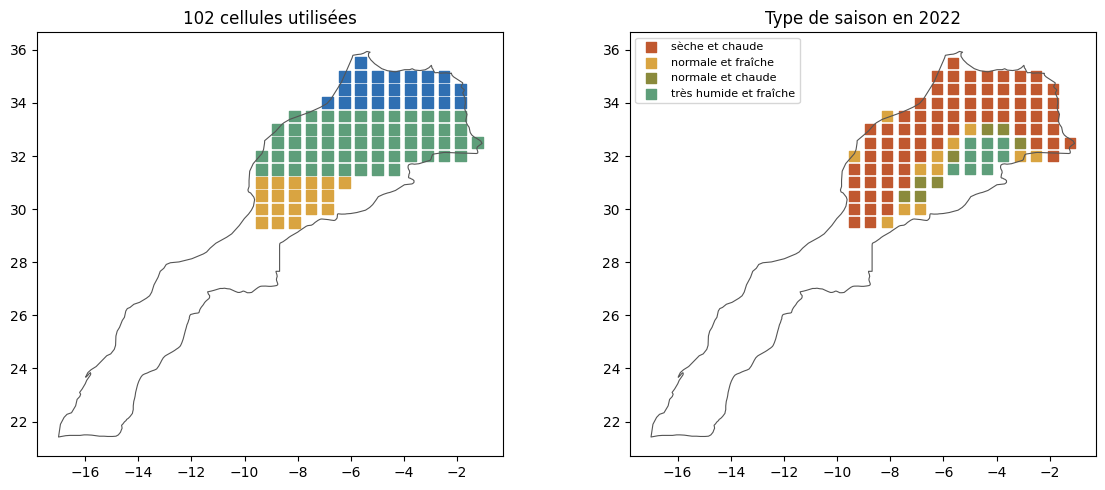

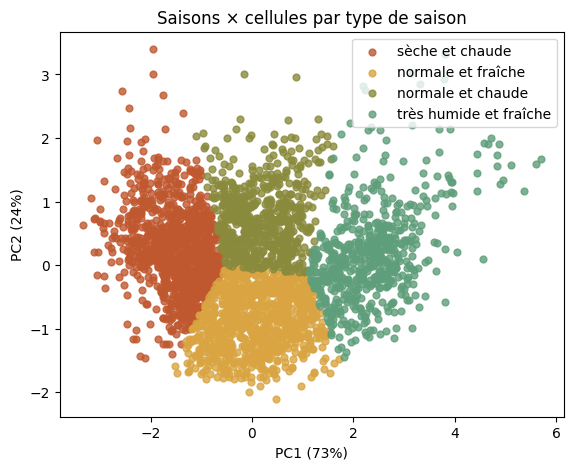

In [19]:
palette = ["#C0582F", "#D9A441", "#8A8A3C", "#5E9E7A", "#2F6FB2", "#6B4FA0"]
cells_df = data.drop_duplicates("point")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(cells_df.lon, cells_df.lat, c=cells_df.region.map({"Nord": "#2F6FB2", "Centre": "#5E9E7A", "Sud": "#D9A441"}), s=60, marker="s")
ax[0].set_title(f"{len(cells_df)} cellules utilisées"); ax[0].set_aspect("equal")
for p in (paths if COUNTRY_FILTER.startswith("Natural") else []):
    v = p.vertices; ax[0].plot(v[:, 0], v[:, 1], c="#555", lw=0.8); ax[1].plot(v[:, 0], v[:, 1], c="#555", lw=0.8)
yr = data[data["season"] == 2022] if (data["season"] == 2022).any() else data[data["season"] == data["season"].max()]
for i, lab in enumerate(ORDER):
    m = yr["label"] == lab
    ax[1].scatter(yr.lon[m], yr.lat[m], s=60, marker="s", c=palette[i % len(palette)], label=lab)
ax[1].set_title(f"Type de saison en {int(yr.season.iloc[0])}"); ax[1].set_aspect("equal"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pca = PCA(n_components=2).fit(Xs_m); P = pca.transform(Xs_m)
plt.figure(figsize=(6.5, 5))
for i, lab in enumerate(ORDER):
    m = data["label"].values == lab
    plt.scatter(P[m, 0], P[m, 1], s=24, alpha=0.8, label=lab, c=palette[i % len(palette)])
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
plt.legend(); plt.title("Saisons × cellules par type de saison"); plt.show()

### 7.6 Verdict

In [20]:
checks = {
    "Stable (ARI bootstrap ≥ %.2f)" % MIN_ARI_BOOT: metrics["ari_boot_mean"] >= MIN_ARI_BOOT,
    "Cellules dominées ≤ %.0f %%" % (100 * MAX_FRAC_DOMINATED): metrics["frac_cells_dominated"] <= MAX_FRAC_DOMINATED,
    "Pas de classe minuscule (≥ %.0f %%)" % (100 * MIN_CLASS_SHARE): metrics["min_class_share"] >= MIN_CLASS_SHARE,
    "Séparation correcte (silhouette ≥ 0,25)": metrics["silhouette"] >= 0.25,
    "Généralise aux nouvelles saisons (ARI ≥ 0,7)": metrics["ari_holdout_seasons"] >= 0.7,
    "Généralise aux nouveaux lieux (ARI moyen ≥ 0,7)": metrics["ari_holdout_cells_mean"] >= 0.7,
    "2022 classée sèche dans la majorité des cellules": metrics["share_cells_2022_dry"] >= 0.5,
    "Beni Mellal : 3 saisons les plus sèches en classe sèche": metrics["beni_mellal_3_driest_in_dry_class"] == 3,
}
for k, ok in checks.items(): print(("OK   " if ok else "À VOIR"), k)
metrics["checks_passed"] = int(sum(checks.values())); metrics["checks_total"] = len(checks)
print(f"\n{metrics['checks_passed']} / {len(checks)} vérifications réussies — {SELECTION}")

OK    Stable (ARI bootstrap ≥ 0.75)
OK    Cellules dominées ≤ 10 %
OK    Pas de classe minuscule (≥ 10 %)
OK    Séparation correcte (silhouette ≥ 0,25)
OK    Généralise aux nouvelles saisons (ARI ≥ 0,7)
OK    Généralise aux nouveaux lieux (ARI moyen ≥ 0,7)
OK    2022 classée sèche dans la majorité des cellules
OK    Beni Mellal : 3 saisons les plus sèches en classe sèche

8 / 8 vérifications réussies — meilleur modèle valide


## 8. Sauvegarde

In [21]:
meta = dict(
    model=f"StandardScaler + {'KMeans' if BEST_ALGO == 'kmeans' else 'GaussianMixture'}",
    algo=BEST_ALGO, k=K, feature_set=str(best.features), features=BEST_FEATURES, raw_features=FEATURES,
    normalization="z-score per cell against a fixed reference period, saved in season_baseline.json",
    reference_seasons=list(REF_SEASONS), baseline_file="season_baseline.json",
    label_map={str(k): v for k, v in label_map.items()}, label_order_dry_to_wet=ORDER,
    label_rule="rain anomaly: < -0.6 sèche, < -0.3 plutôt sèche, <= 0.3 normale, <= 1.0 plutôt humide, else très humide; heat-days anomaly > 0.4 chaude, < -0.4 fraîche",
    selection=SELECTION,
    selection_rules=dict(k_candidates=K_CANDIDATES, min_ari_boot=MIN_ARI_BOOT, max_share_per_cell=MAX_SHARE_PER_CELL,
                         max_frac_dominated=MAX_FRAC_DOMINATED, min_class_share=MIN_CLASS_SHARE),
    thresholds=dict(heat_t_max_c=HEAT_T, dry_day_mm=DRY_MM, max_missing=MAX_MISSING),
    season="Oct-May, labelled by ending year", training_period=[START, END],
    n_cells=int(data["point"].nunique()), n_samples=int(len(data)), grid=dict(lats=LATS, lons=LONS),
    coverage=dict(country="Morocco", country_filter=COUNTRY_FILTER, min_lat=float(min(LATS)),
                  min_season_rain_mm=MIN_SEASON_RAIN,
                  cells=[[float(a), float(b)] for a, b in data.drop_duplicates("point")[["lat", "lon"]].values]),
    usage="Outside the listed cells (nearest cell farther than ~0.5°), results are not reliable.",
    metrics={k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()},
    sklearn_version=sklearn.__version__,
    trained_at=dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    data_source="NASA POWER daily API, community AG",
)
mean_b, std_b = BASELINE
baseline_json = {p: dict(lat=coords[p][0], lon=coords[p][1],
                         mean={f: round(float(mean_b.loc[p, f]), 4) for f in FEATURES},
                         std={f: (None if pd.isna(std_b.loc[p, f]) else round(float(std_b.loc[p, f]), 4)) for f in FEATURES})
                 for p in mean_b.index}
(OUT / "season_baseline.json").write_text(json.dumps(baseline_json, indent=1))
joblib.dump(model, OUT / "season_model.joblib")
(OUT / "season_model_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
for f in sorted(OUT.glob("*.*")): print(" -", f.name)

 - .virtual_documents
 - model_selection.csv
 - season_baseline.json
 - season_features.csv
 - season_model.joblib
 - season_model_meta.json


### Test de rechargement

Comme le fera l'API. Ne chargez jamais un `.joblib` qui ne vient pas de vous : joblib peut exécuter du code.

In [22]:
# Simulation de l'API : features brutes d'un point + référence sauvegardée -> type de saison
base2 = json.loads((OUT / "season_baseline.json").read_text())
row = data[data["point"] == ref_name].iloc[-1]
z = [(row[f[:-5]] - base2[ref_name]["mean"][f[:-5]]) / base2[ref_name]["std"][f[:-5]] for f in BEST_FEATURES]
print("Saison", int(row.season), "à", ref_name, "->", label_map[int(model.predict(pd.DataFrame([z], columns=BEST_FEATURES))[0])])
m2 = joblib.load(OUT / "season_model.joblib")
meta2 = json.loads((OUT / "season_model_meta.json").read_text())
assert meta2["sklearn_version"] == sklearn.__version__
pred = [meta2["label_map"][str(int(c))] for c in m2.predict(bm.merge(data)[meta2["features"]])]
assert pred == list(bm["label"]), "Le modèle rechargé ne donne pas les mêmes classes"
print("Modèle rechargé : mêmes classes pour Beni Mellal ->", pred)

Saison 2025 à C057 -> sèche et chaude
Modèle rechargé : mêmes classes pour Beni Mellal -> ['très humide et fraîche', 'très humide et fraîche', 'normale et fraîche', 'sèche et chaude', 'normale et fraîche', 'normale et fraîche', 'normale et fraîche', 'normale et chaude', 'normale et fraîche', 'sèche et chaude', 'normale et chaude', 'normale et fraîche', 'normale et fraîche', 'très humide et fraîche', 'très humide et fraîche', 'très humide et fraîche', 'normale et chaude', 'très humide et fraîche', 'sèche et chaude', 'normale et chaude', 'sèche et chaude', 'sèche et chaude', 'normale et fraîche', 'sèche et chaude', 'sèche et chaude', 'sèche et chaude', 'sèche et chaude', 'sèche et chaude', 'sèche et chaude', 'sèche et chaude']
